# Complete Weinreb metaclone overview before analysis

The authors requested identical sizes for all time-resolved metaclone UMAPs, a complete overview before analysis, and no silent omission of MC4/MC11. The five family grids below cover all retained metaclones at Days 2/4/6. Every UMAP uses the same axes box, coordinate limits, aspect, marker geometry and typography. Grids have equal height; insert them at equal heights, not equal widths. The seven multilineage metaclones shown in their overview define the downstream analysis cohort directly.

The original dynamics notebook explicitly described an earlier requested five-metaclone comparison; its hard-coded list propagated to manuscript composition and pseudotime panels. The later atlas showed seven. This revision resolves that mismatch, without retrospectively claiming that the prior five-member analysis covered all seven.

Existing micromamba **chronoclone**, `/path/to/ChronoClone/.runtime/chronoclone`, kernel **chronoclone-paper**. Exact versions print below. Execute:
```sh
JUPYTER_PATH=/path/to/ChronoClone/.runtime/jupyter /path/to/ChronoClone/.runtime/chronoclone/bin/jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone-paper /path/to/ChronoClone/analysis_workspace/weinreb/20260916_complete_metaclone_overview/complete_overview_and_analysis.ipynb
```

Density keeps the author's assigned-cell reference, 100 nearest neighbors and within-metaclone color maximum across days. It is not a between-metaclone abundance scale. Statistical comparisons use clone medians, retain the established twelve-test BH family, and explicitly report support. Branch restriction defines the estimand; low-support groups remain displayed. No expression analysis or new embedding is run. Historical results are preserved.


In [1]:
from pathlib import Path
import os,sys,json,hashlib,platform,importlib.metadata as im
ROOT=Path('/path/to/ChronoClone')
OUT=ROOT/'analysis_workspace/weinreb/20260916_complete_metaclone_overview'
FIG=OUT/'figures';TABLE_DIR=OUT/'tables';FIGURE_DIR=FIG
for p in [FIG,TABLE_DIR,OUT/'reports']:p.mkdir(exist_ok=True)
os.environ['MPLCONFIGDIR']=str(OUT/'matplotlib_cache')
import numpy as np,pandas as pd,anndata as ad,matplotlib as mpl
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from IPython.display import display
from PIL import Image
ENV=ROOT/'.runtime/chronoclone'
assert Path(sys.executable).resolve()==(ENV/'bin/python').resolve()
print({'environment':'chronoclone','path':str(ENV),'kernel':'chronoclone-paper','Python':platform.python_version(),**{p:im.version(p) for p in ['anndata','numpy','pandas','matplotlib','scipy','scikit-learn','statsmodels']}})
def sha256(p):return hashlib.sha256(Path(p).read_bytes()).hexdigest()
SOURCE=ROOT/'reference_workspace/data/klein_metaclone_palantir_trajectories.h5ad'
assert sha256(SOURCE)=='4cb08c12dc70f5c3789a75a09a6399db06b3f6efe18147b9f2cca0908ba93911'
a=ad.read_h5ad(SOURCE,backed='r');obs=a.obs.copy();U=np.asarray(a.obsm['X_umap']).copy();state_order=list(obs.cell_type.cat.categories);a.file.close()
cell_type_order=state_order
required_columns=['day','cell_type','cell_type_weinreb','LARRY_ID','metaclone','palantir_pseudotime','mask_Baso','mask_Neu','mask_Mono']
obs['metaclone']=pd.to_numeric(obs.metaclone);obs['day']=pd.to_numeric(obs.day)
GROUPS={'neutrophil':[9,14,16,22,1],'monocyte':[12,7,8,6],'erythroid_mk':[10,17,23],'basophil':[13],'multilineage':[0,2,5,3,18,4,11]}
ALL_MCS=[m for group in GROUPS.values() for m in group];DAYS=[2,4,6]
assert len(ALL_MCS)==len(set(ALL_MCS))==20
assert set(ALL_MCS)==set(obs.loc[obs.metaclone.ge(0),'metaclone'].astype(int))
assigned=obs.metaclone.ge(0).to_numpy();full_umap=U[assigned];mc_vals=obs.loc[assigned,'metaclone'].to_numpy();day_vals=obs.loc[assigned,'day'].to_numpy()
nbrs=NearestNeighbors(n_neighbors=100,algorithm='ball_tree').fit(full_umap)
PLOT_XLIM=(U[:,0].min()-1,U[:,0].max()+1);PLOT_YLIM=(U[:,1].min()-1,U[:,1].max()+1)
PALETTE=pd.read_csv(ROOT/'ChronoClone_paper/analysis/weinreb/inputs/manuscript_metaclone_palette.csv').set_index('label').color.to_dict()
MC_COLORS={m:PALETTE[f'MC{m}'] for m in ALL_MCS}
mpl.rcParams.update({'svg.fonttype':'none','font.family':'DejaVu Sans','font.size':13,'figure.facecolor':'white','savefig.facecolor':'white','axes.spines.top':False,'axes.spines.right':False})
geometry=[];density_support=[];panel_records=[]
support=obs[obs.metaclone.isin(ALL_MCS)].groupby(['metaclone','day'],observed=True).agg(cells=('LARRY_ID','size'),clones=('LARRY_ID','nunique')).reindex(pd.MultiIndex.from_product([ALL_MCS,DAYS],names=['metaclone','day']),fill_value=0).reset_index()
support.to_csv(TABLE_DIR/'all_metaclone_day_support.csv',index=False)
display(support[support.metaclone.isin([4,11])])


{'environment': 'chronoclone', 'path': '/path/to/ChronoClone/.runtime/chronoclone', 'kernel': 'chronoclone-paper', 'Python': '3.11.15', 'anndata': '0.12.18', 'numpy': '2.4.6', 'pandas': '2.3.3', 'matplotlib': '3.11.0', 'scipy': '1.17.1', 'scikit-learn': '1.9.0', 'statsmodels': '0.14.6'}


,metaclone,day,cells,clones
54,4,2,30,21
55,4,4,79,21
56,4,6,57,10
57,11,2,35,28
58,11,4,92,28
59,11,6,300,28


## Overview: neutrophil

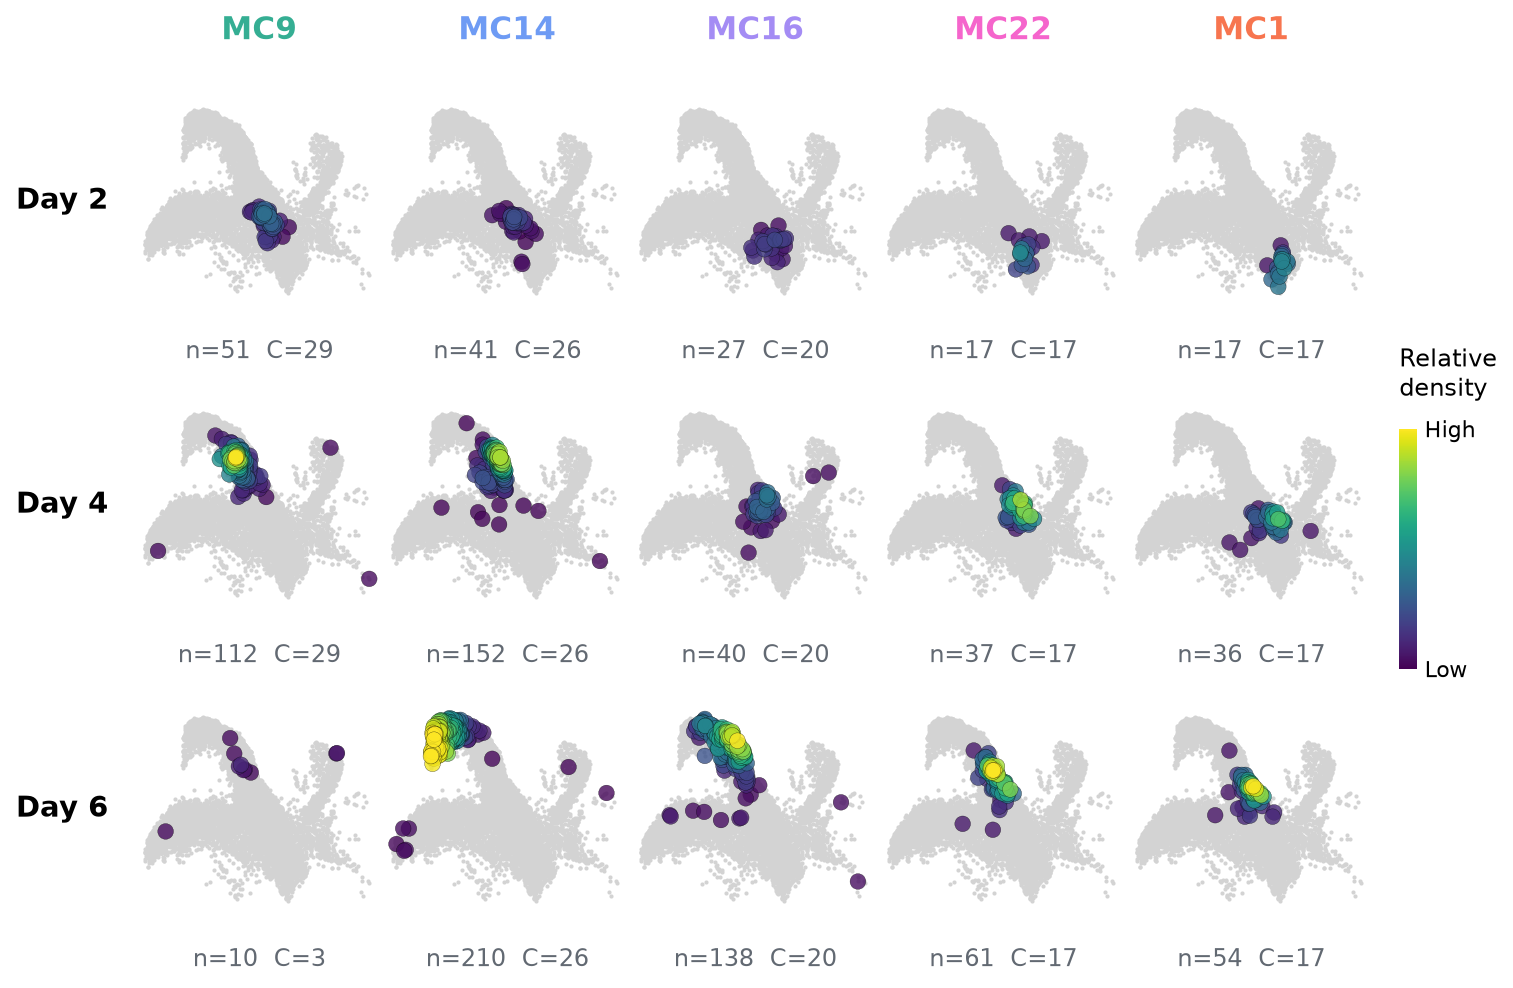

/path/to/ChronoClone/analysis_workspace/weinreb/20260916_complete_metaclone_overview/figures/overview_neutrophil.png


In [2]:
family='neutrophil'
metaclones=GROUPS[family];stem='overview_'+family
# Plot-specific density calculation and scaling match the original author code.
cache={};vmax={}
for mc in metaclones:
    for day in DAYS:
        idx=np.flatnonzero((mc_vals==mc)&(day_vals==day))
        if len(idx):
            neighbors=nbrs.kneighbors(full_umap[idx],return_distance=False)
            dens=np.isin(neighbors,idx).sum(axis=1)
        else:dens=np.array([],dtype=int)
        cache[mc,day]=(idx,dens)
    vmax[mc]=max(5,max((d.max() if len(d) else 0) for (_,d) in [cache[mc,day] for day in DAYS]))
# Fixed physical axes and row/column pitch; column count changes canvas width only.
fw=1.05+1.55*len(metaclones)+.95;fh=6.15
fig=plt.figure(figsize=(fw,fh),dpi=160)
labels=[]
for j,mc in enumerate(metaclones):
    labels.append(fig.text((1.05+1.55*(j+.5))/fw,1-.10/fh,f'MC{mc}',ha='center',va='top',fontsize=14,fontweight='bold',color=MC_COLORS[mc]))
    for i,day in enumerate(DAYS):
        bottom=fh-.45-1.9*(i+1)+.26
        ax=fig.add_axes([(1.05+1.55*j)/fw,bottom/fh,1.52/fw,1.66/fh])
        ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
        ax.scatter(U[:,0],U[:,1],s=3.5,c='lightgrey',linewidths=0,rasterized=True,zorder=0)
        idx,dens=cache[mc,day];order=np.argsort(dens,kind='stable')
        if len(idx):ax.scatter(full_umap[idx[order],0],full_umap[idx[order],1],c=dens[order],cmap='viridis',vmin=0,vmax=vmax[mc],s=50,alpha=.8,edgecolors='black',linewidths=.15,rasterized=False,zorder=2)
        ncl=obs[(obs.metaclone==mc)&(obs.day==day)].LARRY_ID.nunique()
        labels.append(fig.text((1.05+1.55*(j+.5))/fw,(bottom-.035)/fh,f'n={len(idx)}  C={ncl}',ha='center',va='top',fontsize=11,color='#626972'))
        if j==0:labels.append(fig.text(.88/fw,(bottom+.83)/fh,f'Day {day}',ha='right',va='center',fontsize=13,fontweight='bold'))
        fig.canvas.draw();box=ax.get_window_extent()
        geometry.append({'stem':stem,'mc':mc,'day':day,'width_pt':box.width/fig.dpi*72,'height_pt':box.height/fig.dpi*72})
        density_support.append({'mc':mc,'day':day,'cells':len(idx),'clones':ncl,'density_vmax':int(vmax[mc])})
bar=fig.add_axes([(1.05+1.55*len(metaclones)+.15)/fw,.32,.11/fw,1.5/fh])
cb=fig.colorbar(plt.cm.ScalarMappable(norm=mpl.colors.Normalize(0,1),cmap='viridis'),cax=bar)
cb.set_ticks([0,1],labels=['Low','High']);cb.ax.tick_params(labelsize=10,length=0);cb.outline.set_visible(False)
labels.append(fig.text((1.05+1.55*len(metaclones)+.15)/fw,.32+1.5/fh+.025,'Relative\ndensity',fontsize=11,va='bottom'))
fig.canvas.draw()
for label in labels:
    box=label.get_window_extent(fig.canvas.get_renderer());assert box.x0>=0 and box.y0>=0 and box.x1<=fig.bbox.width and box.y1<=fig.bbox.height,(stem,label.get_text())
fig.savefig(FIG/f'{stem}.svg');fig.savefig(FIG/f'{stem}.png',dpi=300)
display(fig);plt.close(fig)
panel_records.append({'stem':stem,'metaclones':metaclones,'svg_sha256':sha256(FIG/f'{stem}.svg'),'png_sha256':sha256(FIG/f'{stem}.png')})
print(FIG/f'{stem}.png')


## Overview: monocyte

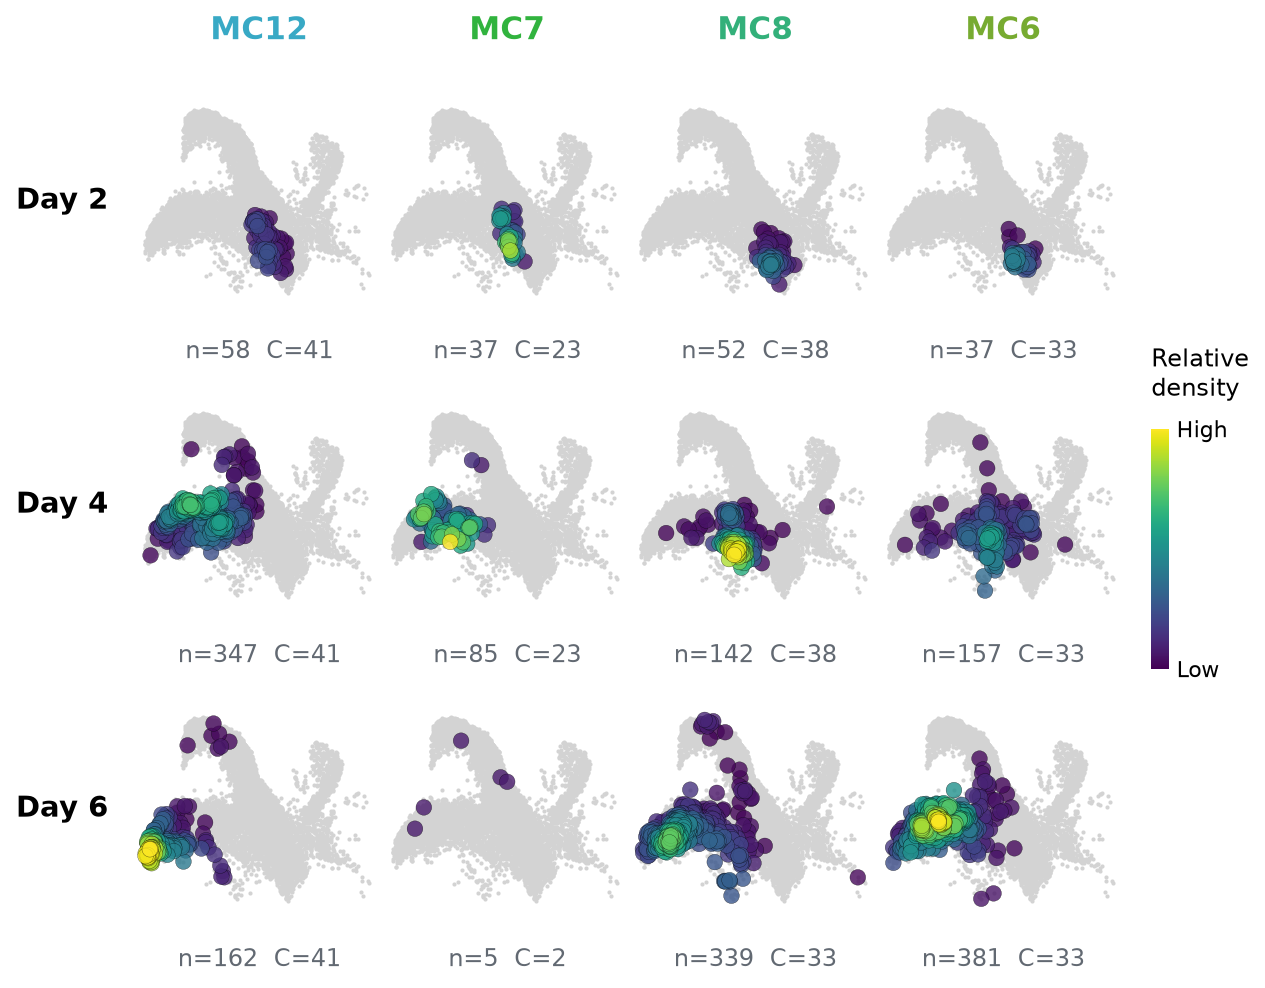

/path/to/ChronoClone/analysis_workspace/weinreb/20260916_complete_metaclone_overview/figures/overview_monocyte.png


In [3]:
family='monocyte'
metaclones=GROUPS[family];stem='overview_'+family
# Plot-specific density calculation and scaling match the original author code.
cache={};vmax={}
for mc in metaclones:
    for day in DAYS:
        idx=np.flatnonzero((mc_vals==mc)&(day_vals==day))
        if len(idx):
            neighbors=nbrs.kneighbors(full_umap[idx],return_distance=False)
            dens=np.isin(neighbors,idx).sum(axis=1)
        else:dens=np.array([],dtype=int)
        cache[mc,day]=(idx,dens)
    vmax[mc]=max(5,max((d.max() if len(d) else 0) for (_,d) in [cache[mc,day] for day in DAYS]))
# Fixed physical axes and row/column pitch; column count changes canvas width only.
fw=1.05+1.55*len(metaclones)+.95;fh=6.15
fig=plt.figure(figsize=(fw,fh),dpi=160)
labels=[]
for j,mc in enumerate(metaclones):
    labels.append(fig.text((1.05+1.55*(j+.5))/fw,1-.10/fh,f'MC{mc}',ha='center',va='top',fontsize=14,fontweight='bold',color=MC_COLORS[mc]))
    for i,day in enumerate(DAYS):
        bottom=fh-.45-1.9*(i+1)+.26
        ax=fig.add_axes([(1.05+1.55*j)/fw,bottom/fh,1.52/fw,1.66/fh])
        ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
        ax.scatter(U[:,0],U[:,1],s=3.5,c='lightgrey',linewidths=0,rasterized=True,zorder=0)
        idx,dens=cache[mc,day];order=np.argsort(dens,kind='stable')
        if len(idx):ax.scatter(full_umap[idx[order],0],full_umap[idx[order],1],c=dens[order],cmap='viridis',vmin=0,vmax=vmax[mc],s=50,alpha=.8,edgecolors='black',linewidths=.15,rasterized=False,zorder=2)
        ncl=obs[(obs.metaclone==mc)&(obs.day==day)].LARRY_ID.nunique()
        labels.append(fig.text((1.05+1.55*(j+.5))/fw,(bottom-.035)/fh,f'n={len(idx)}  C={ncl}',ha='center',va='top',fontsize=11,color='#626972'))
        if j==0:labels.append(fig.text(.88/fw,(bottom+.83)/fh,f'Day {day}',ha='right',va='center',fontsize=13,fontweight='bold'))
        fig.canvas.draw();box=ax.get_window_extent()
        geometry.append({'stem':stem,'mc':mc,'day':day,'width_pt':box.width/fig.dpi*72,'height_pt':box.height/fig.dpi*72})
        density_support.append({'mc':mc,'day':day,'cells':len(idx),'clones':ncl,'density_vmax':int(vmax[mc])})
bar=fig.add_axes([(1.05+1.55*len(metaclones)+.15)/fw,.32,.11/fw,1.5/fh])
cb=fig.colorbar(plt.cm.ScalarMappable(norm=mpl.colors.Normalize(0,1),cmap='viridis'),cax=bar)
cb.set_ticks([0,1],labels=['Low','High']);cb.ax.tick_params(labelsize=10,length=0);cb.outline.set_visible(False)
labels.append(fig.text((1.05+1.55*len(metaclones)+.15)/fw,.32+1.5/fh+.025,'Relative\ndensity',fontsize=11,va='bottom'))
fig.canvas.draw()
for label in labels:
    box=label.get_window_extent(fig.canvas.get_renderer());assert box.x0>=0 and box.y0>=0 and box.x1<=fig.bbox.width and box.y1<=fig.bbox.height,(stem,label.get_text())
fig.savefig(FIG/f'{stem}.svg');fig.savefig(FIG/f'{stem}.png',dpi=300)
display(fig);plt.close(fig)
panel_records.append({'stem':stem,'metaclones':metaclones,'svg_sha256':sha256(FIG/f'{stem}.svg'),'png_sha256':sha256(FIG/f'{stem}.png')})
print(FIG/f'{stem}.png')


## Overview: erythroid mk

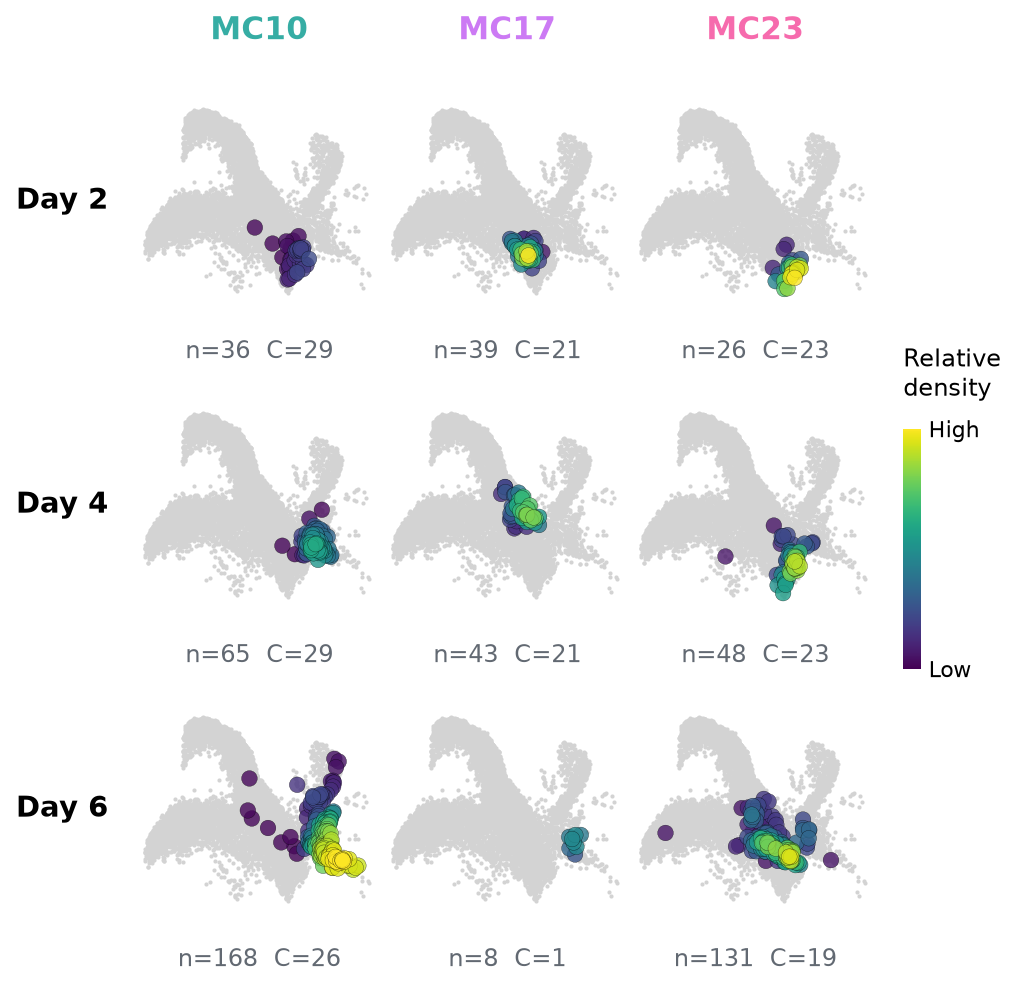

/path/to/ChronoClone/analysis_workspace/weinreb/20260916_complete_metaclone_overview/figures/overview_erythroid_mk.png


In [4]:
family='erythroid_mk'
metaclones=GROUPS[family];stem='overview_'+family
# Plot-specific density calculation and scaling match the original author code.
cache={};vmax={}
for mc in metaclones:
    for day in DAYS:
        idx=np.flatnonzero((mc_vals==mc)&(day_vals==day))
        if len(idx):
            neighbors=nbrs.kneighbors(full_umap[idx],return_distance=False)
            dens=np.isin(neighbors,idx).sum(axis=1)
        else:dens=np.array([],dtype=int)
        cache[mc,day]=(idx,dens)
    vmax[mc]=max(5,max((d.max() if len(d) else 0) for (_,d) in [cache[mc,day] for day in DAYS]))
# Fixed physical axes and row/column pitch; column count changes canvas width only.
fw=1.05+1.55*len(metaclones)+.95;fh=6.15
fig=plt.figure(figsize=(fw,fh),dpi=160)
labels=[]
for j,mc in enumerate(metaclones):
    labels.append(fig.text((1.05+1.55*(j+.5))/fw,1-.10/fh,f'MC{mc}',ha='center',va='top',fontsize=14,fontweight='bold',color=MC_COLORS[mc]))
    for i,day in enumerate(DAYS):
        bottom=fh-.45-1.9*(i+1)+.26
        ax=fig.add_axes([(1.05+1.55*j)/fw,bottom/fh,1.52/fw,1.66/fh])
        ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
        ax.scatter(U[:,0],U[:,1],s=3.5,c='lightgrey',linewidths=0,rasterized=True,zorder=0)
        idx,dens=cache[mc,day];order=np.argsort(dens,kind='stable')
        if len(idx):ax.scatter(full_umap[idx[order],0],full_umap[idx[order],1],c=dens[order],cmap='viridis',vmin=0,vmax=vmax[mc],s=50,alpha=.8,edgecolors='black',linewidths=.15,rasterized=False,zorder=2)
        ncl=obs[(obs.metaclone==mc)&(obs.day==day)].LARRY_ID.nunique()
        labels.append(fig.text((1.05+1.55*(j+.5))/fw,(bottom-.035)/fh,f'n={len(idx)}  C={ncl}',ha='center',va='top',fontsize=11,color='#626972'))
        if j==0:labels.append(fig.text(.88/fw,(bottom+.83)/fh,f'Day {day}',ha='right',va='center',fontsize=13,fontweight='bold'))
        fig.canvas.draw();box=ax.get_window_extent()
        geometry.append({'stem':stem,'mc':mc,'day':day,'width_pt':box.width/fig.dpi*72,'height_pt':box.height/fig.dpi*72})
        density_support.append({'mc':mc,'day':day,'cells':len(idx),'clones':ncl,'density_vmax':int(vmax[mc])})
bar=fig.add_axes([(1.05+1.55*len(metaclones)+.15)/fw,.32,.11/fw,1.5/fh])
cb=fig.colorbar(plt.cm.ScalarMappable(norm=mpl.colors.Normalize(0,1),cmap='viridis'),cax=bar)
cb.set_ticks([0,1],labels=['Low','High']);cb.ax.tick_params(labelsize=10,length=0);cb.outline.set_visible(False)
labels.append(fig.text((1.05+1.55*len(metaclones)+.15)/fw,.32+1.5/fh+.025,'Relative\ndensity',fontsize=11,va='bottom'))
fig.canvas.draw()
for label in labels:
    box=label.get_window_extent(fig.canvas.get_renderer());assert box.x0>=0 and box.y0>=0 and box.x1<=fig.bbox.width and box.y1<=fig.bbox.height,(stem,label.get_text())
fig.savefig(FIG/f'{stem}.svg');fig.savefig(FIG/f'{stem}.png',dpi=300)
display(fig);plt.close(fig)
panel_records.append({'stem':stem,'metaclones':metaclones,'svg_sha256':sha256(FIG/f'{stem}.svg'),'png_sha256':sha256(FIG/f'{stem}.png')})
print(FIG/f'{stem}.png')


## Overview: basophil

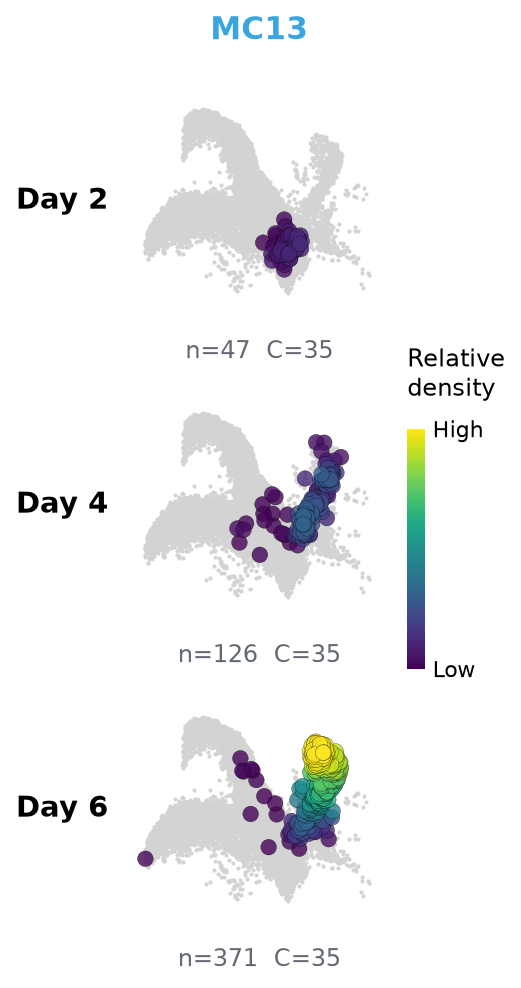

/path/to/ChronoClone/analysis_workspace/weinreb/20260916_complete_metaclone_overview/figures/overview_basophil.png


In [5]:
family='basophil'
metaclones=GROUPS[family];stem='overview_'+family
# Plot-specific density calculation and scaling match the original author code.
cache={};vmax={}
for mc in metaclones:
    for day in DAYS:
        idx=np.flatnonzero((mc_vals==mc)&(day_vals==day))
        if len(idx):
            neighbors=nbrs.kneighbors(full_umap[idx],return_distance=False)
            dens=np.isin(neighbors,idx).sum(axis=1)
        else:dens=np.array([],dtype=int)
        cache[mc,day]=(idx,dens)
    vmax[mc]=max(5,max((d.max() if len(d) else 0) for (_,d) in [cache[mc,day] for day in DAYS]))
# Fixed physical axes and row/column pitch; column count changes canvas width only.
fw=1.05+1.55*len(metaclones)+.95;fh=6.15
fig=plt.figure(figsize=(fw,fh),dpi=160)
labels=[]
for j,mc in enumerate(metaclones):
    labels.append(fig.text((1.05+1.55*(j+.5))/fw,1-.10/fh,f'MC{mc}',ha='center',va='top',fontsize=14,fontweight='bold',color=MC_COLORS[mc]))
    for i,day in enumerate(DAYS):
        bottom=fh-.45-1.9*(i+1)+.26
        ax=fig.add_axes([(1.05+1.55*j)/fw,bottom/fh,1.52/fw,1.66/fh])
        ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
        ax.scatter(U[:,0],U[:,1],s=3.5,c='lightgrey',linewidths=0,rasterized=True,zorder=0)
        idx,dens=cache[mc,day];order=np.argsort(dens,kind='stable')
        if len(idx):ax.scatter(full_umap[idx[order],0],full_umap[idx[order],1],c=dens[order],cmap='viridis',vmin=0,vmax=vmax[mc],s=50,alpha=.8,edgecolors='black',linewidths=.15,rasterized=False,zorder=2)
        ncl=obs[(obs.metaclone==mc)&(obs.day==day)].LARRY_ID.nunique()
        labels.append(fig.text((1.05+1.55*(j+.5))/fw,(bottom-.035)/fh,f'n={len(idx)}  C={ncl}',ha='center',va='top',fontsize=11,color='#626972'))
        if j==0:labels.append(fig.text(.88/fw,(bottom+.83)/fh,f'Day {day}',ha='right',va='center',fontsize=13,fontweight='bold'))
        fig.canvas.draw();box=ax.get_window_extent()
        geometry.append({'stem':stem,'mc':mc,'day':day,'width_pt':box.width/fig.dpi*72,'height_pt':box.height/fig.dpi*72})
        density_support.append({'mc':mc,'day':day,'cells':len(idx),'clones':ncl,'density_vmax':int(vmax[mc])})
bar=fig.add_axes([(1.05+1.55*len(metaclones)+.15)/fw,.32,.11/fw,1.5/fh])
cb=fig.colorbar(plt.cm.ScalarMappable(norm=mpl.colors.Normalize(0,1),cmap='viridis'),cax=bar)
cb.set_ticks([0,1],labels=['Low','High']);cb.ax.tick_params(labelsize=10,length=0);cb.outline.set_visible(False)
labels.append(fig.text((1.05+1.55*len(metaclones)+.15)/fw,.32+1.5/fh+.025,'Relative\ndensity',fontsize=11,va='bottom'))
fig.canvas.draw()
for label in labels:
    box=label.get_window_extent(fig.canvas.get_renderer());assert box.x0>=0 and box.y0>=0 and box.x1<=fig.bbox.width and box.y1<=fig.bbox.height,(stem,label.get_text())
fig.savefig(FIG/f'{stem}.svg');fig.savefig(FIG/f'{stem}.png',dpi=300)
display(fig);plt.close(fig)
panel_records.append({'stem':stem,'metaclones':metaclones,'svg_sha256':sha256(FIG/f'{stem}.svg'),'png_sha256':sha256(FIG/f'{stem}.png')})
print(FIG/f'{stem}.png')


## Overview: multilineage

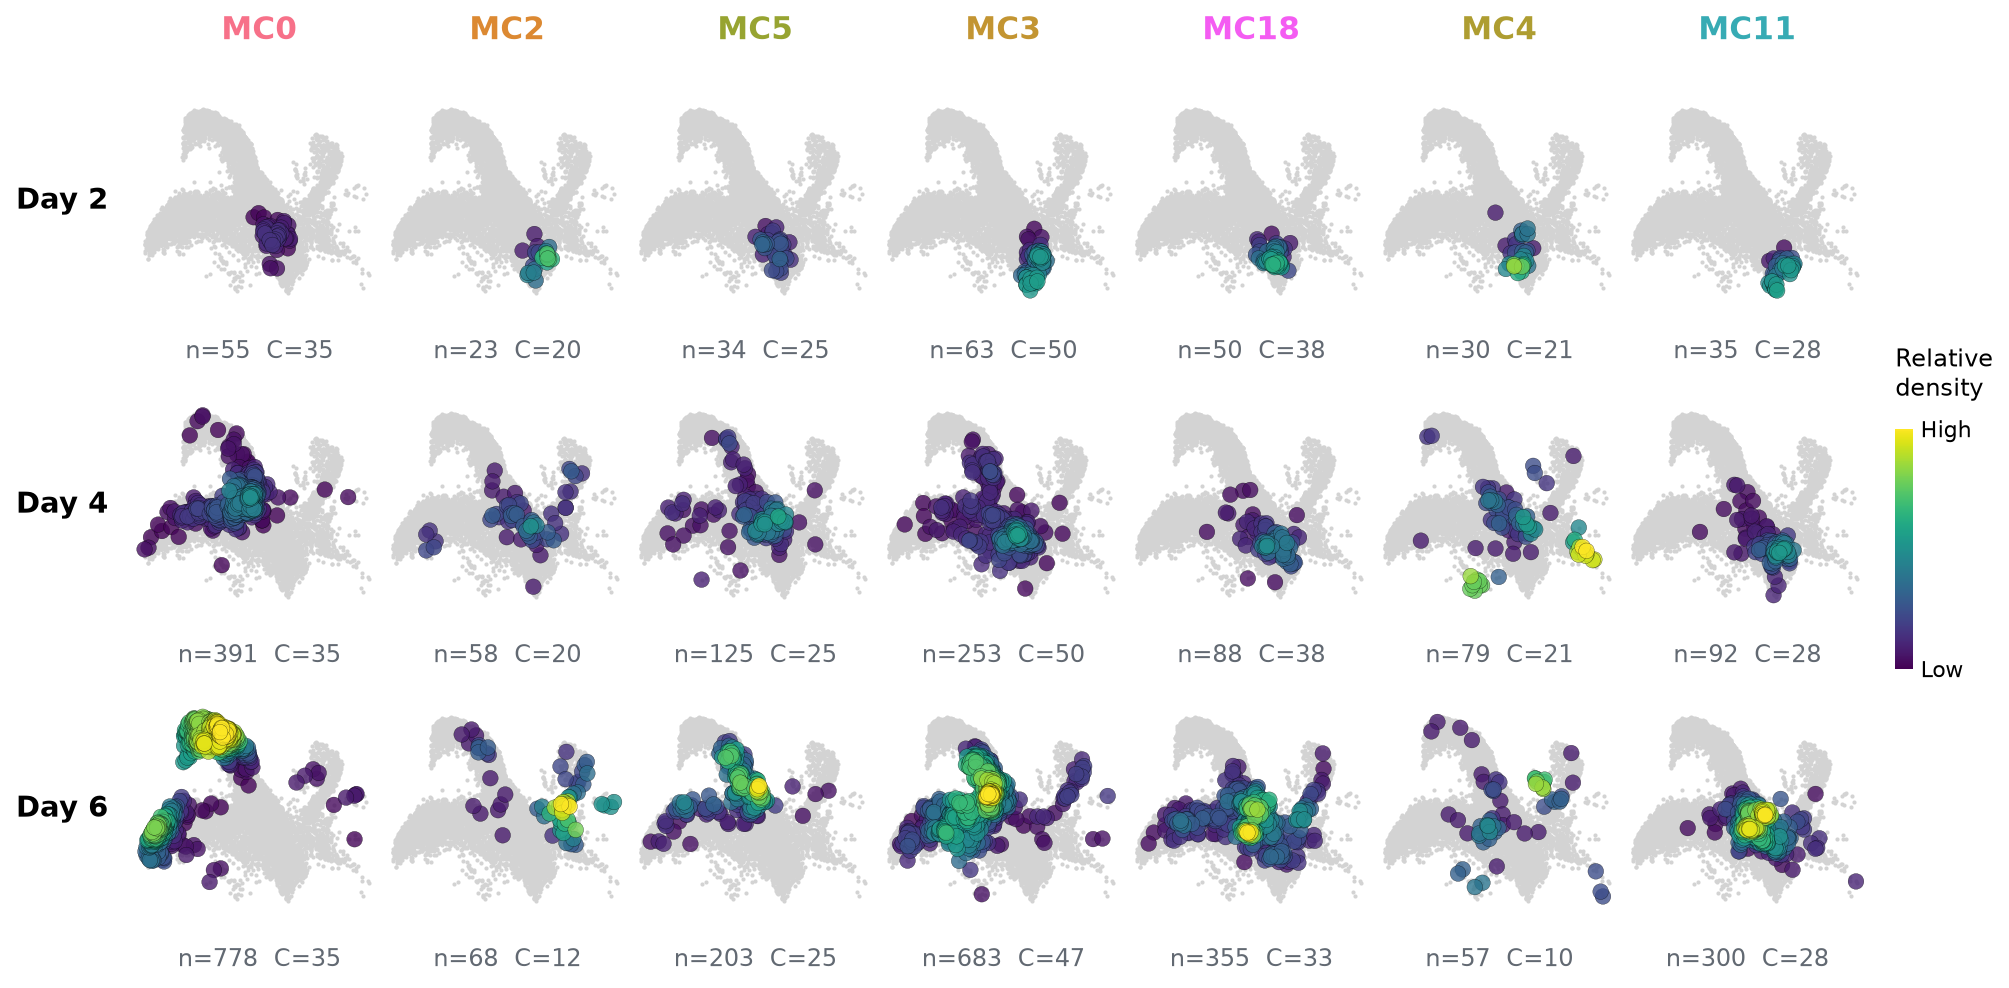

/path/to/ChronoClone/analysis_workspace/weinreb/20260916_complete_metaclone_overview/figures/overview_multilineage.png


In [6]:
family='multilineage'
metaclones=GROUPS[family];stem='overview_'+family
# Plot-specific density calculation and scaling match the original author code.
cache={};vmax={}
for mc in metaclones:
    for day in DAYS:
        idx=np.flatnonzero((mc_vals==mc)&(day_vals==day))
        if len(idx):
            neighbors=nbrs.kneighbors(full_umap[idx],return_distance=False)
            dens=np.isin(neighbors,idx).sum(axis=1)
        else:dens=np.array([],dtype=int)
        cache[mc,day]=(idx,dens)
    vmax[mc]=max(5,max((d.max() if len(d) else 0) for (_,d) in [cache[mc,day] for day in DAYS]))
# Fixed physical axes and row/column pitch; column count changes canvas width only.
fw=1.05+1.55*len(metaclones)+.95;fh=6.15
fig=plt.figure(figsize=(fw,fh),dpi=160)
labels=[]
for j,mc in enumerate(metaclones):
    labels.append(fig.text((1.05+1.55*(j+.5))/fw,1-.10/fh,f'MC{mc}',ha='center',va='top',fontsize=14,fontweight='bold',color=MC_COLORS[mc]))
    for i,day in enumerate(DAYS):
        bottom=fh-.45-1.9*(i+1)+.26
        ax=fig.add_axes([(1.05+1.55*j)/fw,bottom/fh,1.52/fw,1.66/fh])
        ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
        ax.scatter(U[:,0],U[:,1],s=3.5,c='lightgrey',linewidths=0,rasterized=True,zorder=0)
        idx,dens=cache[mc,day];order=np.argsort(dens,kind='stable')
        if len(idx):ax.scatter(full_umap[idx[order],0],full_umap[idx[order],1],c=dens[order],cmap='viridis',vmin=0,vmax=vmax[mc],s=50,alpha=.8,edgecolors='black',linewidths=.15,rasterized=False,zorder=2)
        ncl=obs[(obs.metaclone==mc)&(obs.day==day)].LARRY_ID.nunique()
        labels.append(fig.text((1.05+1.55*(j+.5))/fw,(bottom-.035)/fh,f'n={len(idx)}  C={ncl}',ha='center',va='top',fontsize=11,color='#626972'))
        if j==0:labels.append(fig.text(.88/fw,(bottom+.83)/fh,f'Day {day}',ha='right',va='center',fontsize=13,fontweight='bold'))
        fig.canvas.draw();box=ax.get_window_extent()
        geometry.append({'stem':stem,'mc':mc,'day':day,'width_pt':box.width/fig.dpi*72,'height_pt':box.height/fig.dpi*72})
        density_support.append({'mc':mc,'day':day,'cells':len(idx),'clones':ncl,'density_vmax':int(vmax[mc])})
bar=fig.add_axes([(1.05+1.55*len(metaclones)+.15)/fw,.32,.11/fw,1.5/fh])
cb=fig.colorbar(plt.cm.ScalarMappable(norm=mpl.colors.Normalize(0,1),cmap='viridis'),cax=bar)
cb.set_ticks([0,1],labels=['Low','High']);cb.ax.tick_params(labelsize=10,length=0);cb.outline.set_visible(False)
labels.append(fig.text((1.05+1.55*len(metaclones)+.15)/fw,.32+1.5/fh+.025,'Relative\ndensity',fontsize=11,va='bottom'))
fig.canvas.draw()
for label in labels:
    box=label.get_window_extent(fig.canvas.get_renderer());assert box.x0>=0 and box.y0>=0 and box.x1<=fig.bbox.width and box.y1<=fig.bbox.height,(stem,label.get_text())
fig.savefig(FIG/f'{stem}.svg');fig.savefig(FIG/f'{stem}.png',dpi=300)
display(fig);plt.close(fig)
panel_records.append({'stem':stem,'metaclones':metaclones,'svg_sha256':sha256(FIG/f'{stem}.svg'),'png_sha256':sha256(FIG/f'{stem}.png')})
print(FIG/f'{stem}.png')


## Analysis cohort and display palette
The complete multilineage overview above defines the analysis membership. No additional metaclone selection occurs below.

In [7]:
# Lock the target cohort and save cell-level analysis metadata
TARGET_MCS = GROUPS['multilineage'].copy()
TARGET_DAYS = [4, 6]
BRANCHES = ["Baso", "Neu", "Mono"]
MC_COLORS = {
    0: "#f77189", 1: "#f7754f", 2: "#dc8932", 3: "#c39532",
    4: "#ae9d31", 5: "#97a431", 6: "#77ab31", 7: "#31b33e",
    8: "#33b07a", 9: "#35ae93", 10: "#36ada4", 11: "#37abb4",
    12: "#38a9c5", 13: "#3aa5df", 14: "#6e9bf4", 16: "#a48cf4",
    17: "#cc7af4", 18: "#f45cf2", 22: "#f565cc", 23: "#f66bad",
}

analysis_cells = obs.loc[
    obs["metaclone"].isin(TARGET_MCS) & obs["day"].isin(TARGET_DAYS),
    required_columns,
].copy()
analysis_cells["metaclone"] = analysis_cells["metaclone"].astype(int)
analysis_cells["day"] = analysis_cells["day"].astype(int)
analysis_cells["cell_type"] = analysis_cells["cell_type"].astype(str)
analysis_cells["cell_type_weinreb"] = analysis_cells["cell_type_weinreb"].astype(str)
for branch in BRANCHES:
    analysis_cells[f"mask_{branch}"] = analysis_cells[f"mask_{branch}"].astype(bool)
analysis_cells.index.name = "cell"

support = (
    analysis_cells.groupby(["metaclone", "day"], observed=True)
    .agg(n_cells=("LARRY_ID", "size"), n_clones=("LARRY_ID", "nunique"))
    .reindex(pd.MultiIndex.from_product([TARGET_MCS, TARGET_DAYS], names=["metaclone", "day"]))
    .reset_index()
)
assert support["n_cells"].notna().all()
assert support["n_clones"].notna().all()

analysis_cells.reset_index().to_csv(TABLE_DIR / "analysis_cell_metadata.csv", index=False)
support.to_csv(TABLE_DIR / "target_metaclone_day_support.csv", index=False)
display(support)

,metaclone,day,n_cells,n_clones
0,0,4,391,35
1,0,6,778,35
2,2,4,58,20
3,2,6,68,12
4,5,4,125,25
5,5,6,203,25
6,3,4,253,50
7,3,6,683,47
8,18,4,88,38
9,18,6,355,33


In [8]:
STATE_LABELS={'prog_1':'HSPCs','prog_2':'HSPCs','prog_3':'Prog 3','prog_4':'Prog 4','early_prog_Neu':'Early Neu prog','prog_Neu':'Neu prog','prog_Mono':'Mono prog','prog_Baso_Eos':'Baso/Eos prog','prog_Baso_Meg_Ery_Mast':'Baso/Mk/Ery/Mast prog','prog_DC_Mono':'DC/Mono prog','prog_Ly_pDC':'Ly/pDC prog','prog_Meg_Ery':'Mk/Ery prog','Meg':'Mk'}
DISPLAY_COLORS={'HSPCs':'#787878','Prog 3':'#a7a7a7','Prog 4':'#c5c5c5','Neu':'#ec8b23','Early Neu prog':'#f3c685','Neu prog':'#f3a84d','Mono':'#c83f59','Mono prog':'#e8879b','DC/Mono prog':'#b55d76','Baso':'#289646','Baso/Eos prog':'#78bd85','Baso/Mk/Ery/Mast prog':'#8cc493','Ery':'#408bc0','Mk':'#2664a7','Mk/Ery prog':'#89b6d5','Mast':'#874dad','Eos':'#8f663e','DC':'#776792','Ly':'#259994','Ly/pDC prog':'#85c5bf'}
STATE_STAGES={
    'HSPCs and early progenitors':['HSPCs','Prog 3','Prog 4'],
    'Multilineage-associated progenitors':['Baso/Mk/Ery/Mast prog','Ly/pDC prog','DC/Mono prog','Mk/Ery prog','Baso/Eos prog'],
    'Lineage-associated progenitors':['Early Neu prog','Neu prog','Mono prog'],
    'Differentiated cells':['Baso','DC','Eos','Ery','Ly','Mast','Mk','Mono','Neu'],
}
display_order=list(dict.fromkeys(STATE_LABELS.get(s,s) for s in state_order))
assert set(display_order)==set(DISPLAY_COLORS)
pd.DataFrame({'label':display_order,'color':[DISPLAY_COLORS[x] for x in display_order]}).to_csv(OUT/'tables/cell_state_display_palette.csv',index=False)
display(pd.DataFrame({'label':display_order,'color':[DISPLAY_COLORS[x] for x in display_order]}))

,label,color
0,Baso,#289646
1,DC,#776792
2,Eos,#8f663e
3,Ery,#408bc0
4,Ly,#259994
5,Mast,#874dad
6,Mk,#2664a7
7,Mono,#c83f59
8,Neu,#ec8b23
9,Early Neu prog,#f3c685


In [9]:
# Compute clone-balanced and pooled-cell fine-state composition
fine_order_present = [
    state for state in cell_type_order if state in set(analysis_cells["cell_type"])
]

clone_counts = (
    analysis_cells.groupby(["metaclone", "day", "LARRY_ID", "cell_type"], observed=True)
    .size()
    .rename("n_cells")
    .reset_index()
)
clone_totals = (
    clone_counts.groupby(["metaclone", "day", "LARRY_ID"], observed=True)["n_cells"]
    .sum()
    .rename("clone_total")
    .reset_index()
)
clone_composition = clone_counts.merge(
    clone_totals, on=["metaclone", "day", "LARRY_ID"], validate="many_to_one"
)
clone_composition["fraction"] = (
    clone_composition["n_cells"] / clone_composition["clone_total"]
)
clone_complete_index = pd.MultiIndex.from_product(
    [
        TARGET_MCS,
        TARGET_DAYS,
        sorted(analysis_cells["LARRY_ID"].unique()),
        fine_order_present,
    ],
    names=["metaclone", "day", "LARRY_ID", "cell_type"],
)
# Only retain clone IDs that actually occur in each metaclone/day.
observed_clone_index = (
    analysis_cells[["metaclone", "day", "LARRY_ID"]]
    .drop_duplicates()
    .assign(_key=1)
    .merge(pd.DataFrame({"cell_type": fine_order_present, "_key": 1}), on="_key")
    .drop(columns="_key")
)
clone_complete = observed_clone_index.merge(
    clone_composition[["metaclone", "day", "LARRY_ID", "cell_type", "fraction"]],
    on=["metaclone", "day", "LARRY_ID", "cell_type"],
    how="left",
)
clone_complete["fraction"] = clone_complete["fraction"].fillna(0.0)

clone_balanced_composition = (
    clone_complete.groupby(["metaclone", "day", "cell_type"], observed=True)["fraction"]
    .mean()
    .rename("fraction")
    .reset_index()
)
pooled_cell_composition = (
    analysis_cells.groupby(["metaclone", "day", "cell_type"], observed=True)
    .size()
    .rename("n_cells")
    .reset_index()
)
pooled_cell_composition["fraction"] = pooled_cell_composition.groupby(
    ["metaclone", "day"], observed=True
)["n_cells"].transform(lambda values: values / values.sum())

clone_balanced_composition.to_csv(
    TABLE_DIR / "fine_state_composition_clone_balanced.csv", index=False
)
pooled_cell_composition.to_csv(
    TABLE_DIR / "fine_state_composition_pooled_cells.csv", index=False
)

clone_sums = clone_balanced_composition.groupby(
    ["metaclone", "day"], observed=True
)["fraction"].sum()
pooled_sums = pooled_cell_composition.groupby(
    ["metaclone", "day"], observed=True
)["fraction"].sum()
assert np.allclose(clone_sums.values, 1.0)
assert np.allclose(pooled_sums.values, 1.0)
print("Clone-balanced composition rows:", len(clone_balanced_composition))
print("Pooled-cell sensitivity rows:", len(pooled_cell_composition))
print("Maximum absolute composition sum error:",
      max(float((clone_sums - 1).abs().max()), float((pooled_sums - 1).abs().max())))

Clone-balanced composition rows: 294
Pooled-cell sensitivity rows: 159
Maximum absolute composition sum error: 1.1102230246251565e-16


,display_order,cell_state,stage,color
0,1,HSPCs,HSPCs and early progenitors,#787878
1,2,Prog 3,HSPCs and early progenitors,#a7a7a7
2,3,Prog 4,HSPCs and early progenitors,#c5c5c5
3,4,Baso/Mk/Ery/Mast prog,Multilineage-associated progenitors,#8cc493
4,5,Ly/pDC prog,Multilineage-associated progenitors,#85c5bf
5,6,DC/Mono prog,Multilineage-associated progenitors,#b55d76
6,7,Mk/Ery prog,Multilineage-associated progenitors,#89b6d5
7,8,Baso/Eos prog,Multilineage-associated progenitors,#78bd85
8,9,Early Neu prog,Lineage-associated progenitors,#f3c685
9,10,Neu prog,Lineage-associated progenitors,#f3a84d


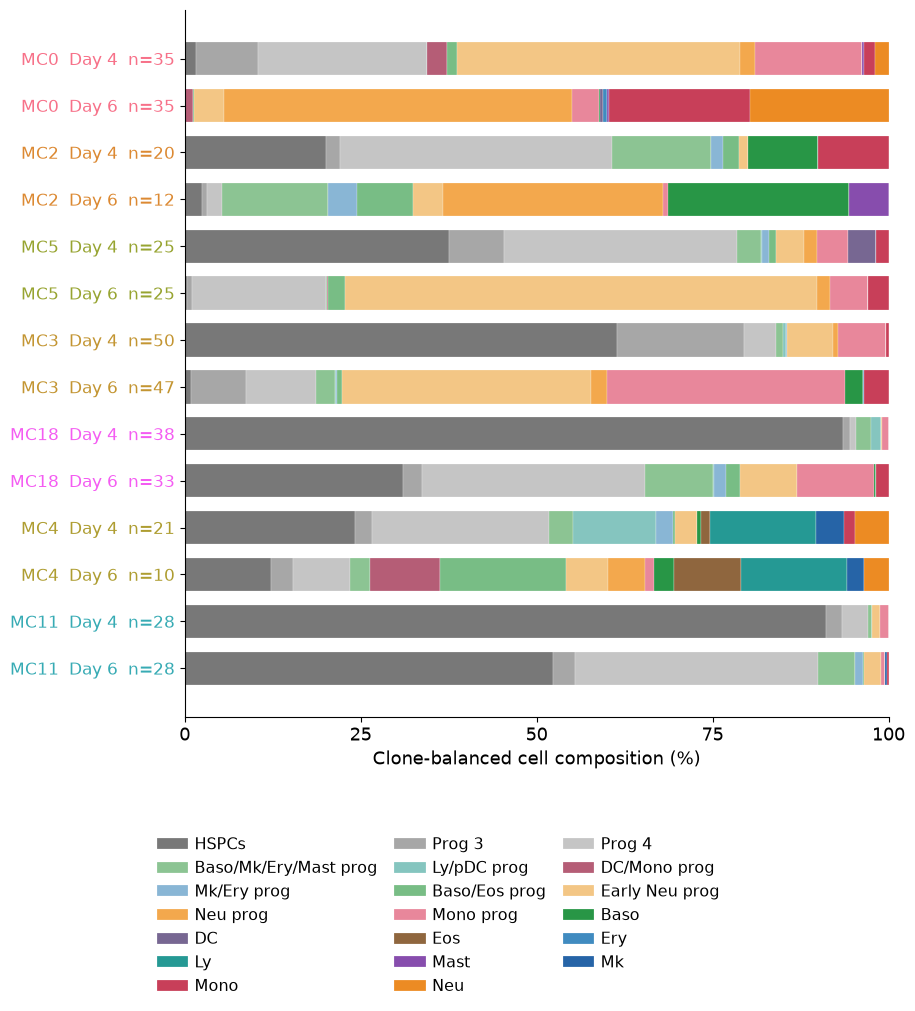

/path/to/ChronoClone/analysis_workspace/weinreb/20260916_complete_metaclone_overview/figures/figure_3a_hspc_pooled_composition.svg


In [10]:
STEM='figure_3a_hspc_pooled_composition'
source=SOURCE
original=clone_balanced_composition.copy()
plot_data=original.assign(display_state=original.cell_type.replace(STATE_LABELS)).groupby(['metaclone','day','display_state'],as_index=False).fraction.sum()
order=[(mc,day) for mc in TARGET_MCS for day in [4,6]]
matrix=plot_data.pivot(index=['metaclone','day'],columns='display_state',values='fraction').reindex(index=pd.MultiIndex.from_tuples(order,names=['metaclone','day']),columns=display_order).fillna(0)
assert np.allclose(matrix.sum(axis=1),1,atol=1e-10)
# Annotation-based display hierarchy, not a newly fitted temporal trajectory.
# Terminal cell types share one maturity tier; their within-tier order does
# not claim that one differentiated lineage is more mature than another.
state_stages=STATE_STAGES
stack_order=[state for states in state_stages.values() for state in states]
assert len(stack_order)==len(display_order) and set(stack_order)==set(display_order)
order_table=pd.DataFrame([{'display_order':i+1,'cell_state':state,'stage':next(stage for stage,states in state_stages.items() if state in states),'color':DISPLAY_COLORS[state]} for i,state in enumerate(stack_order)])
order_table.to_csv(OUT/'tables/figure_3a_cell_state_display_order.csv',index=False)
display(order_table)
support=obs[(obs.metaclone.isin(TARGET_MCS))&(obs.day.isin([4,6]))].groupby(['metaclone','day']).LARRY_ID.nunique()
fig,ax=plt.subplots(figsize=(9.2,10.4))
fig.subplots_adjust(left=.22,right=.985,top=.98,bottom=.30)
y=np.arange(len(order));left=np.zeros(len(order))
for state in stack_order:
    values=matrix[state].to_numpy()*100
    ax.barh(y,values,left=left,color=DISPLAY_COLORS[state],height=.71,edgecolor='white',linewidth=.15,label=state)
    left+=values
labels=[f'MC{mc}  Day {day}  n={int(support.loc[(mc,day)])}' for mc,day in order]
ax.set_yticks(y,labels,fontsize=12);ax.invert_yaxis()
for tick,(mc,day) in zip(ax.get_yticklabels(),order): tick.set_color(PALETTE[f'MC{mc}'])
ax.set_xlim(0,100);ax.set_xticks([0,25,50,75,100]);ax.set_xlabel('Clone-balanced cell composition (%)')
handles,legend_labels=ax.get_legend_handles_labels()
legend_indices=[i for column in range(3) for i in range(column,len(stack_order),3)]
ax.legend([handles[i] for i in legend_indices],[legend_labels[i] for i in legend_indices],ncol=3,loc='upper center',bbox_to_anchor=(.36,-.15),frameon=False,fontsize=11.3,handletextpad=.4,columnspacing=1.1)
matrix.reset_index().to_csv(OUT/'tables'/f'{STEM}.csv',index=False)
fig.savefig(FIG/f'{STEM}.svg',bbox_inches='tight',pad_inches=.13)
fig.savefig(FIG/f'{STEM}.png',dpi=300,bbox_inches='tight',pad_inches=.13)
display(fig);plt.close(fig)
panel_records.append({'stem':STEM,'source':str(source.relative_to(ROOT)),'source_sha256':sha256(source),'change':'Linear HSPC display aggregation; common state palette; immature-to-differentiated left-to-right stacking and row-major legend','svg_sha256':sha256(FIG/f'{STEM}.svg'),'png_sha256':sha256(FIG/f'{STEM}.png')})
print(FIG/f'{STEM}.svg')

In [11]:
from scipy.stats import kruskal
from statsmodels.stats.multitest import multipletests
PSEUDOTIME_TEST_DESIGNS={
    'neutrophil_output':{'branch':'Neu','mcs':[1,22,9,16,14],'days':[2,4,6]},
    'monocyte_output':{'branch':'Mono','mcs':[6,8,7,12],'days':[2,4,6]},
    'multilineage_Baso':{'branch':'Baso','mcs':TARGET_MCS,'days':[4,6]},
    'multilineage_Neu':{'branch':'Neu','mcs':TARGET_MCS,'days':[4,6]},
    'multilineage_Mono':{'branch':'Mono','mcs':TARGET_MCS,'days':[4,6]},
}
test_rows=[];test_data=[]
for context,spec in PSEUDOTIME_TEST_DESIGNS.items():
    cells=obs[obs.metaclone.isin(spec['mcs']) & obs.day.isin(spec['days']) & obs['mask_'+spec['branch']].astype(bool)].copy()
    cells['pseudotime']=pd.to_numeric(cells.palantir_pseudotime)
    cells=cells[np.isfinite(cells.pseudotime)]
    medians=cells.groupby(['metaclone','day','LARRY_ID'],observed=True,as_index=False).pseudotime.median()
    assert not medians.duplicated(['metaclone','day','LARRY_ID']).any()
    test_data.append(medians.assign(context=context,branch=spec['branch']))
    for day in spec['days']:
        block=medians[medians.day==day]
        arrays={mc:block.loc[block.metaclone==mc,'pseudotime'].to_numpy(float) for mc in spec['mcs']}
        included=[mc for mc in spec['mcs'] if len(arrays[mc])>=3]
        supported=len(included)>=2
        result=kruskal(*(arrays[mc] for mc in included)) if supported else None
        test_rows.append({'context':context,'branch':spec['branch'],'day':day,'metaclones_declared':'|'.join('MC'+str(mc) for mc in spec['mcs']),'metaclones_tested':'|'.join('MC'+str(mc) for mc in included),'metaclones_below_support':'|'.join('MC'+str(mc) for mc in spec['mcs'] if mc not in included),'n_clones_by_metaclone':json.dumps({str(mc):len(arrays[mc]) for mc in spec['mcs']}),'estimable':supported,'kruskal_H':float(result.statistic) if supported else np.nan,'p_value':float(result.pvalue) if supported else 1.0})
pseudotime_tests=pd.DataFrame(test_rows)
assert len(pseudotime_tests)==12
pseudotime_tests['q_value']=multipletests(pseudotime_tests.p_value,method='fdr_bh')[1]
pseudotime_tests['symbol']=['NE' if not row.estimable else '**' if row.q_value<.05 else '*' if row.q_value<.10 else 'ns' for row in pseudotime_tests.itertuples()]
pseudotime_tests['test_family']='12 within-day clone-median Kruskal-Wallis tests'
pseudotime_tests['interpretation']='Conditional within-atlas omnibus difference; not a pairwise or independent-discovery test'
pd.concat(test_data,ignore_index=True).to_csv(OUT/'tables/pseudotime_omnibus_clone_medians.csv',index=False)
pseudotime_tests.to_csv(OUT/'tables/pseudotime_within_day_omnibus_tests.csv',index=False)
display(pseudotime_tests)
print('Recomputed full-cohort tests; historical five-MC files preserved. These q values supersede the old restricted-family annotations.')

,context,branch,day,metaclones_declared,metaclones_tested,metaclones_below_support,n_clones_by_metaclone,estimable,kruskal_H,p_value,q_value,symbol,test_family,interpretation
0,neutrophil_output,Neu,2,MC1|MC22|MC9|MC16|MC14,MC1|MC22|MC9|MC16|MC14,,"{""1"": 17, ""22"": 14, ""9"": 24, ""16"": 13, ""14"": 21}",True,68.777711,4.111274e-14,7.047898e-14,**,12 within-day clone-median Kruskal-Wallis tests,Conditional within-atlas omnibus difference; n...
1,neutrophil_output,Neu,4,MC1|MC22|MC9|MC16|MC14,MC1|MC22|MC9|MC16|MC14,,"{""1"": 16, ""22"": 15, ""9"": 29, ""16"": 20, ""14"": 26}",True,83.130277,3.780453e-17,1.512181e-16,**,12 within-day clone-median Kruskal-Wallis tests,Conditional within-atlas omnibus difference; n...
2,neutrophil_output,Neu,6,MC1|MC22|MC9|MC16|MC14,MC1|MC22|MC16|MC14,MC9,"{""1"": 17, ""22"": 17, ""9"": 2, ""16"": 20, ""14"": 26}",True,71.263620,2.289003e-15,6.867008e-15,**,12 within-day clone-median Kruskal-Wallis tests,Conditional within-atlas omnibus difference; n...
3,monocyte_output,Mono,2,MC6|MC8|MC7|MC12,MC6|MC8|MC7|MC12,,"{""6"": 32, ""8"": 36, ""7"": 9, ""12"": 23}",True,22.582287,4.934401e-05,5.921281e-05,**,12 within-day clone-median Kruskal-Wallis tests,Conditional within-atlas omnibus difference; n...
4,monocyte_output,Mono,4,MC6|MC8|MC7|MC12,MC6|MC8|MC7|MC12,,"{""6"": 24, ""8"": 31, ""7"": 21, ""12"": 41}",True,65.727544,3.505272e-14,7.010545e-14,**,12 within-day clone-median Kruskal-Wallis tests,Conditional within-atlas omnibus difference; n...
5,monocyte_output,Mono,6,MC6|MC8|MC7|MC12,MC6|MC8|MC12,MC7,"{""6"": 29, ""8"": 33, ""7"": 2, ""12"": 41}",True,53.626474,2.265475e-12,3.398212e-12,**,12 within-day clone-median Kruskal-Wallis tests,Conditional within-atlas omnibus difference; n...
6,multilineage_Baso,Baso,4,MC0|MC2|MC5|MC3|MC18|MC4|MC11,MC2|MC5|MC3|MC18|MC4|MC11,MC0,"{""0"": 1, ""2"": 9, ""5"": 4, ""3"": 16, ""18"": 25, ""4...",True,25.041407,1.367920e-04,1.492277e-04,**,12 within-day clone-median Kruskal-Wallis tests,Conditional within-atlas omnibus difference; n...
7,multilineage_Baso,Baso,6,MC0|MC2|MC5|MC3|MC18|MC4|MC11,MC2|MC5|MC3|MC18|MC4|MC11,MC0,"{""0"": 2, ""2"": 7, ""5"": 3, ""3"": 8, ""18"": 12, ""4""...",True,23.844279,2.325937e-04,2.325937e-04,**,12 within-day clone-median Kruskal-Wallis tests,Conditional within-atlas omnibus difference; n...
8,multilineage_Neu,Neu,4,MC0|MC2|MC5|MC3|MC18|MC4|MC11,MC0|MC2|MC5|MC3|MC18|MC4|MC11,,"{""0"": 34, ""2"": 14, ""5"": 21, ""3"": 45, ""18"": 32,...",True,110.732210,1.432019e-21,8.592115e-21,**,12 within-day clone-median Kruskal-Wallis tests,Conditional within-atlas omnibus difference; n...
9,multilineage_Neu,Neu,6,MC0|MC2|MC5|MC3|MC18|MC4|MC11,MC0|MC2|MC5|MC3|MC18|MC4|MC11,,"{""0"": 34, ""2"": 7, ""5"": 25, ""3"": 33, ""18"": 30, ...",True,122.376526,5.161478e-24,6.193773e-23,**,12 within-day clone-median Kruskal-Wallis tests,Conditional within-atlas omnibus difference; n...


Recomputed full-cohort tests; historical five-MC files preserved. These q values supersede the old restricted-family annotations.


## Baso branch pseudotime: all seven multilineage metaclones

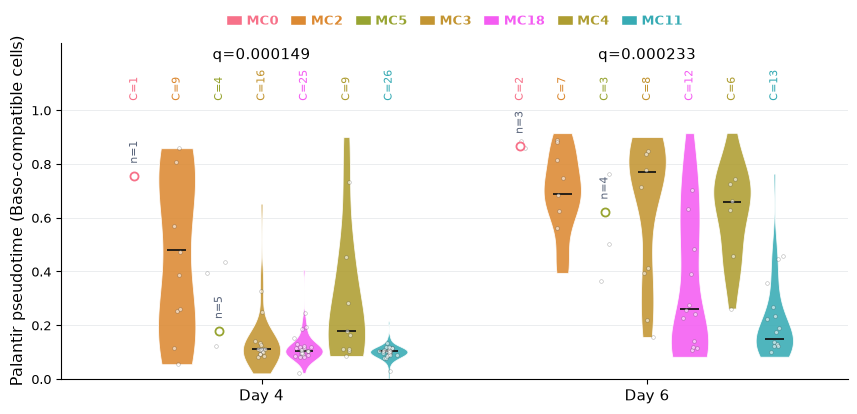

In [12]:
# Plot: Baso branch-compatible cell density along pseudotime
branch = "Baso"
mc_colors = {mc: MC_COLORS[mc] for mc in TARGET_MCS}
branch_cells = analysis_cells[analysis_cells[f"mask_{branch}"]].copy()
branch_cells = branch_cells[
    branch_cells["palantir_pseudotime"].notna()
]
branch_clone_medians = (
    branch_cells.groupby(["metaclone", "day", "LARRY_ID"], observed=True)[
        "palantir_pseudotime"
    ]
    .median()
    .rename("clone_median")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9.2, 4.8))
width = 0.11
rng = np.random.default_rng(20260901)
for day_position, day in enumerate(TARGET_DAYS):
    for mc_position, mc in enumerate(TARGET_MCS):
        x_position = day_position + (mc_position - (len(TARGET_MCS)-1)/2) * width
        values = branch_cells.loc[
            (branch_cells["day"] == day) & (branch_cells["metaclone"] == mc),
            "palantir_pseudotime",
        ].to_numpy()
        clone_values = branch_clone_medians.loc[
            (branch_clone_medians["day"] == day)
            & (branch_clone_medians["metaclone"] == mc),
            "clone_median",
        ].to_numpy()
        if len(values) >= 8 and np.unique(values).size >= 2:
            violin = ax.violinplot(
                [values],
                positions=[x_position],
                widths=width * 0.88,
                showmedians=True,
                showextrema=False,
            )
            for body in violin["bodies"]:
                body.set_facecolor(mc_colors[mc])
                body.set_edgecolor("white")
                body.set_linewidth(0.6)
                body.set_alpha(0.88)
            violin["cmedians"].set_color("#111111")
            violin["cmedians"].set_linewidth(1.25)
        elif len(values) > 0:
            ax.scatter(
                [x_position],
                [float(np.median(values))],
                s=34,
                facecolors="white",
                edgecolors=mc_colors[mc],
                linewidths=1.3,
                zorder=4,
            )
            ax.text(
                x_position,
                min(1.01, float(np.median(values)) + 0.045),
                f"n={len(values)}",
                ha="center",
                va="bottom",
                fontsize=7.6,
                color="#5C677D",
                rotation=90,
            )
        else:
            ax.scatter(
                [x_position], [0.025], marker="x", s=28,
                color="#9AA0A6", linewidths=1.1, zorder=4,
            )
            ax.text(
                x_position, 0.065, "n=0", ha="center", va="bottom",
                fontsize=7.6, color="#7C828A", rotation=90,
            )
        if len(clone_values):
            jitter = rng.normal(0, width * 0.09, size=len(clone_values))
            ax.scatter(
                np.full(len(clone_values), x_position) + jitter,
                clone_values,
                s=7,
                facecolors="white",
                edgecolors="#252525",
                linewidths=0.25,
                alpha=0.55,
                zorder=3,
            )

for dp,day in enumerate(TARGET_DAYS):
    for mp,mc in enumerate(TARGET_MCS):
        count=len(branch_clone_medians[(branch_clone_medians.day==day)&(branch_clone_medians.metaclone==mc)])
        ax.text(dp+(mp-(len(TARGET_MCS)-1)/2)*width,1.035,f'C={count}',ha='center',fontsize=8,color=MC_COLORS[mc],rotation=90,va='bottom')
    test=pseudotime_tests[(pseudotime_tests.context=='multilineage_'+branch)&(pseudotime_tests.day==day)].iloc[0]
    ax.text(dp,1.19,f"q={test.q_value:.3g}" if test.estimable else 'Not estimable',ha='center',fontsize=11)
branch_clone_medians.to_csv(TABLE_DIR/f'{branch.lower()}_clone_medians_complete.csv',index=False)

ax.set_xticks([0, 1])
ax.set_xticklabels(["Day 4", "Day 6"], fontsize=11)
ax.set_xlim(-0.52, 1.52)
ax.set_ylim(0, 1.25);ax.set_yticks(np.linspace(0,1,6))
ax.set_ylabel("Palantir pseudotime (Baso-compatible cells)", fontsize=11.2)
ax.tick_params(axis="y", labelsize=9.5)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#E6E8EB", linewidth=0.7, alpha=0.8)
ax.set_axisbelow(True)
from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor=mc_colors[mc], edgecolor="white", label=f"MC{mc}")
    for mc in TARGET_MCS
]
legend = ax.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.01),
    frameon=False,
    fontsize=9.5,
    ncol=len(TARGET_MCS),
    handlelength=1.2,
    handletextpad=0.35,
    columnspacing=0.9,
)
for label, mc in zip(legend.get_texts(), TARGET_MCS):
    label.set_color(mc_colors[mc])
    label.set_fontweight("bold")
fig.subplots_adjust(left=0.13, right=0.985, bottom=0.16, top=0.86)
branch_stem = FIGURE_DIR / "weinreb_multilineage_baso_branch_pseudotime"
fig.savefig(branch_stem.with_suffix(".svg"), bbox_inches="tight", pad_inches=0.06)
fig.savefig(branch_stem.with_suffix(".png"), dpi=300, bbox_inches="tight", pad_inches=0.06)
display(fig);plt.close(fig)
panel_records.append({'stem':branch_stem.name,'metaclones':TARGET_MCS,'svg_sha256':sha256(branch_stem.with_suffix('.svg')),'png_sha256':sha256(branch_stem.with_suffix('.png'))})

## Neu branch pseudotime: all seven multilineage metaclones

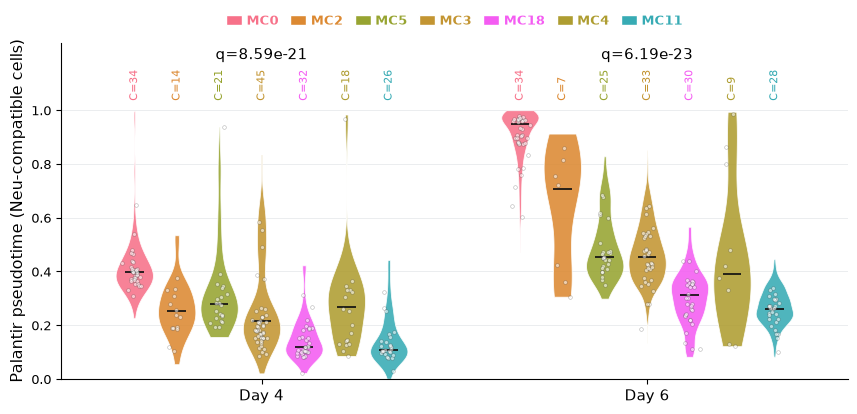

In [13]:
# Plot: Neu branch-compatible cell density along pseudotime
branch = "Neu"
mc_colors = {mc: MC_COLORS[mc] for mc in TARGET_MCS}
branch_cells = analysis_cells[analysis_cells[f"mask_{branch}"]].copy()
branch_cells = branch_cells[
    branch_cells["palantir_pseudotime"].notna()
]
branch_clone_medians = (
    branch_cells.groupby(["metaclone", "day", "LARRY_ID"], observed=True)[
        "palantir_pseudotime"
    ]
    .median()
    .rename("clone_median")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9.2, 4.8))
width = 0.11
rng = np.random.default_rng(20260901)
for day_position, day in enumerate(TARGET_DAYS):
    for mc_position, mc in enumerate(TARGET_MCS):
        x_position = day_position + (mc_position - (len(TARGET_MCS)-1)/2) * width
        values = branch_cells.loc[
            (branch_cells["day"] == day) & (branch_cells["metaclone"] == mc),
            "palantir_pseudotime",
        ].to_numpy()
        clone_values = branch_clone_medians.loc[
            (branch_clone_medians["day"] == day)
            & (branch_clone_medians["metaclone"] == mc),
            "clone_median",
        ].to_numpy()
        if len(values) >= 8 and np.unique(values).size >= 2:
            violin = ax.violinplot(
                [values],
                positions=[x_position],
                widths=width * 0.88,
                showmedians=True,
                showextrema=False,
            )
            for body in violin["bodies"]:
                body.set_facecolor(mc_colors[mc])
                body.set_edgecolor("white")
                body.set_linewidth(0.6)
                body.set_alpha(0.88)
            violin["cmedians"].set_color("#111111")
            violin["cmedians"].set_linewidth(1.25)
        elif len(values) > 0:
            ax.scatter(
                [x_position],
                [float(np.median(values))],
                s=34,
                facecolors="white",
                edgecolors=mc_colors[mc],
                linewidths=1.3,
                zorder=4,
            )
            ax.text(
                x_position,
                min(1.01, float(np.median(values)) + 0.045),
                f"n={len(values)}",
                ha="center",
                va="bottom",
                fontsize=7.6,
                color="#5C677D",
                rotation=90,
            )
        else:
            ax.scatter(
                [x_position], [0.025], marker="x", s=28,
                color="#9AA0A6", linewidths=1.1, zorder=4,
            )
            ax.text(
                x_position, 0.065, "n=0", ha="center", va="bottom",
                fontsize=7.6, color="#7C828A", rotation=90,
            )
        if len(clone_values):
            jitter = rng.normal(0, width * 0.09, size=len(clone_values))
            ax.scatter(
                np.full(len(clone_values), x_position) + jitter,
                clone_values,
                s=7,
                facecolors="white",
                edgecolors="#252525",
                linewidths=0.25,
                alpha=0.55,
                zorder=3,
            )

for dp,day in enumerate(TARGET_DAYS):
    for mp,mc in enumerate(TARGET_MCS):
        count=len(branch_clone_medians[(branch_clone_medians.day==day)&(branch_clone_medians.metaclone==mc)])
        ax.text(dp+(mp-(len(TARGET_MCS)-1)/2)*width,1.035,f'C={count}',ha='center',fontsize=8,color=MC_COLORS[mc],rotation=90,va='bottom')
    test=pseudotime_tests[(pseudotime_tests.context=='multilineage_'+branch)&(pseudotime_tests.day==day)].iloc[0]
    ax.text(dp,1.19,f"q={test.q_value:.3g}" if test.estimable else 'Not estimable',ha='center',fontsize=11)
branch_clone_medians.to_csv(TABLE_DIR/f'{branch.lower()}_clone_medians_complete.csv',index=False)

ax.set_xticks([0, 1])
ax.set_xticklabels(["Day 4", "Day 6"], fontsize=11)
ax.set_xlim(-0.52, 1.52)
ax.set_ylim(0, 1.25);ax.set_yticks(np.linspace(0,1,6))
ax.set_ylabel("Palantir pseudotime (Neu-compatible cells)", fontsize=11.2)
ax.tick_params(axis="y", labelsize=9.5)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#E6E8EB", linewidth=0.7, alpha=0.8)
ax.set_axisbelow(True)
from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor=mc_colors[mc], edgecolor="white", label=f"MC{mc}")
    for mc in TARGET_MCS
]
legend = ax.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.01),
    frameon=False,
    fontsize=9.5,
    ncol=len(TARGET_MCS),
    handlelength=1.2,
    handletextpad=0.35,
    columnspacing=0.9,
)
for label, mc in zip(legend.get_texts(), TARGET_MCS):
    label.set_color(mc_colors[mc])
    label.set_fontweight("bold")
fig.subplots_adjust(left=0.13, right=0.985, bottom=0.16, top=0.86)
branch_stem = FIGURE_DIR / "weinreb_multilineage_neu_branch_pseudotime"
fig.savefig(branch_stem.with_suffix(".svg"), bbox_inches="tight", pad_inches=0.06)
fig.savefig(branch_stem.with_suffix(".png"), dpi=300, bbox_inches="tight", pad_inches=0.06)
display(fig);plt.close(fig)
panel_records.append({'stem':branch_stem.name,'metaclones':TARGET_MCS,'svg_sha256':sha256(branch_stem.with_suffix('.svg')),'png_sha256':sha256(branch_stem.with_suffix('.png'))})

## Mono branch pseudotime: all seven multilineage metaclones

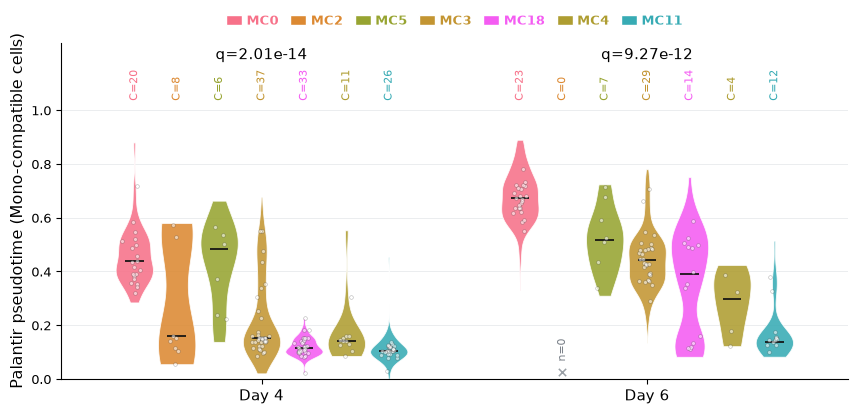

In [14]:
# Plot: Mono branch-compatible cell density along pseudotime
branch = "Mono"
mc_colors = {mc: MC_COLORS[mc] for mc in TARGET_MCS}
branch_cells = analysis_cells[analysis_cells[f"mask_{branch}"]].copy()
branch_cells = branch_cells[
    branch_cells["palantir_pseudotime"].notna()
]
branch_clone_medians = (
    branch_cells.groupby(["metaclone", "day", "LARRY_ID"], observed=True)[
        "palantir_pseudotime"
    ]
    .median()
    .rename("clone_median")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9.2, 4.8))
width = 0.11
rng = np.random.default_rng(20260901)
for day_position, day in enumerate(TARGET_DAYS):
    for mc_position, mc in enumerate(TARGET_MCS):
        x_position = day_position + (mc_position - (len(TARGET_MCS)-1)/2) * width
        values = branch_cells.loc[
            (branch_cells["day"] == day) & (branch_cells["metaclone"] == mc),
            "palantir_pseudotime",
        ].to_numpy()
        clone_values = branch_clone_medians.loc[
            (branch_clone_medians["day"] == day)
            & (branch_clone_medians["metaclone"] == mc),
            "clone_median",
        ].to_numpy()
        if len(values) >= 8 and np.unique(values).size >= 2:
            violin = ax.violinplot(
                [values],
                positions=[x_position],
                widths=width * 0.88,
                showmedians=True,
                showextrema=False,
            )
            for body in violin["bodies"]:
                body.set_facecolor(mc_colors[mc])
                body.set_edgecolor("white")
                body.set_linewidth(0.6)
                body.set_alpha(0.88)
            violin["cmedians"].set_color("#111111")
            violin["cmedians"].set_linewidth(1.25)
        elif len(values) > 0:
            ax.scatter(
                [x_position],
                [float(np.median(values))],
                s=34,
                facecolors="white",
                edgecolors=mc_colors[mc],
                linewidths=1.3,
                zorder=4,
            )
            ax.text(
                x_position,
                min(1.01, float(np.median(values)) + 0.045),
                f"n={len(values)}",
                ha="center",
                va="bottom",
                fontsize=7.6,
                color="#5C677D",
                rotation=90,
            )
        else:
            ax.scatter(
                [x_position], [0.025], marker="x", s=28,
                color="#9AA0A6", linewidths=1.1, zorder=4,
            )
            ax.text(
                x_position, 0.065, "n=0", ha="center", va="bottom",
                fontsize=7.6, color="#7C828A", rotation=90,
            )
        if len(clone_values):
            jitter = rng.normal(0, width * 0.09, size=len(clone_values))
            ax.scatter(
                np.full(len(clone_values), x_position) + jitter,
                clone_values,
                s=7,
                facecolors="white",
                edgecolors="#252525",
                linewidths=0.25,
                alpha=0.55,
                zorder=3,
            )

for dp,day in enumerate(TARGET_DAYS):
    for mp,mc in enumerate(TARGET_MCS):
        count=len(branch_clone_medians[(branch_clone_medians.day==day)&(branch_clone_medians.metaclone==mc)])
        ax.text(dp+(mp-(len(TARGET_MCS)-1)/2)*width,1.035,f'C={count}',ha='center',fontsize=8,color=MC_COLORS[mc],rotation=90,va='bottom')
    test=pseudotime_tests[(pseudotime_tests.context=='multilineage_'+branch)&(pseudotime_tests.day==day)].iloc[0]
    ax.text(dp,1.19,f"q={test.q_value:.3g}" if test.estimable else 'Not estimable',ha='center',fontsize=11)
branch_clone_medians.to_csv(TABLE_DIR/f'{branch.lower()}_clone_medians_complete.csv',index=False)

ax.set_xticks([0, 1])
ax.set_xticklabels(["Day 4", "Day 6"], fontsize=11)
ax.set_xlim(-0.52, 1.52)
ax.set_ylim(0, 1.25);ax.set_yticks(np.linspace(0,1,6))
ax.set_ylabel("Palantir pseudotime (Mono-compatible cells)", fontsize=11.2)
ax.tick_params(axis="y", labelsize=9.5)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#E6E8EB", linewidth=0.7, alpha=0.8)
ax.set_axisbelow(True)
from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor=mc_colors[mc], edgecolor="white", label=f"MC{mc}")
    for mc in TARGET_MCS
]
legend = ax.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.01),
    frameon=False,
    fontsize=9.5,
    ncol=len(TARGET_MCS),
    handlelength=1.2,
    handletextpad=0.35,
    columnspacing=0.9,
)
for label, mc in zip(legend.get_texts(), TARGET_MCS):
    label.set_color(mc_colors[mc])
    label.set_fontweight("bold")
fig.subplots_adjust(left=0.13, right=0.985, bottom=0.16, top=0.86)
branch_stem = FIGURE_DIR / "weinreb_multilineage_mono_branch_pseudotime"
fig.savefig(branch_stem.with_suffix(".svg"), bbox_inches="tight", pad_inches=0.06)
fig.savefig(branch_stem.with_suffix(".png"), dpi=300, bbox_inches="tight", pad_inches=0.06)
display(fig);plt.close(fig)
panel_records.append({'stem':branch_stem.name,'metaclones':TARGET_MCS,'svg_sha256':sha256(branch_stem.with_suffix('.svg')),'png_sha256':sha256(branch_stem.with_suffix('.png'))})

## Completeness and geometry checks

In [15]:
g=pd.DataFrame(geometry);d=pd.DataFrame(density_support)
assert len(g)==60 and not g[['mc','day']].duplicated().any()
assert set(g.mc)==set(ALL_MCS)
assert np.allclose(g.width_pt,g.width_pt.iloc[0],rtol=1e-12) and np.allclose(g.height_pt,g.height_pt.iloc[0],rtol=1e-12)
assert set(TARGET_MCS)==set(GROUPS['multilineage']) and {4,11}.issubset(TARGET_MCS)
assert set(clone_balanced_composition.metaclone)==set(TARGET_MCS)
# Original five groups retain exactly the same clone-balanced composition.
legacy=pd.read_csv(ROOT/'analysis_workspace/weinreb/weinreb_multilineage_metaclone_dynamics_20260901/tables/fine_state_composition_clone_balanced.csv')
current=clone_balanced_composition[clone_balanced_composition.metaclone.isin([0,2,5,3,18])]
keys=['metaclone','day','cell_type']
audit=legacy.merge(current,on=keys,suffixes=('_old','_new'),validate='one_to_one')
assert len(audit)==len(legacy) and np.allclose(audit.fraction_old,audit.fraction_new,rtol=1e-12,atol=1e-14)
g.to_csv(TABLE_DIR/'umap_dimensions.csv',index=False);d.to_csv(TABLE_DIR/'density_support.csv',index=False)
qc={'retained_metaclones':ALL_MCS,'umap_count':len(g),'umap_width_pt':float(g.width_pt.iloc[0]),'umap_height_pt':float(g.height_pt.iloc[0]),'complete_multilineage_cohort':TARGET_MCS,'original_five_composition_unchanged':True,'all_20_shown_before_analysis':True,'outputs':panel_records,'source_sha256':sha256(SOURCE)}
(OUT/'reports/validation.json').write_text(json.dumps(qc,indent=2))
display(qc)
display(pseudotime_tests[pseudotime_tests.context.str.startswith('multilineage')])


{'retained_metaclones': [9,
  14,
  16,
  22,
  1,
  12,
  7,
  8,
  6,
  10,
  17,
  23,
  13,
  0,
  2,
  5,
  3,
  18,
  4,
  11],
 'umap_count': 60,
 'umap_width_pt': 109.44000000000001,
 'umap_height_pt': 91.44540563185906,
 'complete_multilineage_cohort': [0, 2, 5, 3, 18, 4, 11],
 'original_five_composition_unchanged': True,
 'all_20_shown_before_analysis': True,
 'outputs': [{'stem': 'overview_neutrophil',
   'metaclones': [9, 14, 16, 22, 1],
   'svg_sha256': '1b9c6e3d4379524f97246d872c3e9c2a7ea9746a6f01be1cbfc0a1ed9795ba05',
   'png_sha256': '4d1b107765d18016b544e58921cf4da6451ea055687cf8e836838d212c4b0654'},
  {'stem': 'overview_monocyte',
   'metaclones': [12, 7, 8, 6],
   'svg_sha256': 'afd494d6f02b9b4d446e44ca5707649f00d3283eb3aa3270f275659783ae79cf',
   'png_sha256': '35b9d7b24c68f6968745ede0a768ecb450d9e632b9a6fb6a7bff6e55f72996bf'},
  {'stem': 'overview_erythroid_mk',
   'metaclones': [10, 17, 23],
   'svg_sha256': 'bd8b8c9d7fb12b416b215537490ebb0fccd110b9f14240dd85b9f37

,context,branch,day,metaclones_declared,metaclones_tested,metaclones_below_support,n_clones_by_metaclone,estimable,kruskal_H,p_value,q_value,symbol,test_family,interpretation
6,multilineage_Baso,Baso,4,MC0|MC2|MC5|MC3|MC18|MC4|MC11,MC2|MC5|MC3|MC18|MC4|MC11,MC0,"{""0"": 1, ""2"": 9, ""5"": 4, ""3"": 16, ""18"": 25, ""4...",True,25.041407,1.367920e-04,1.492277e-04,**,12 within-day clone-median Kruskal-Wallis tests,Conditional within-atlas omnibus difference; n...
7,multilineage_Baso,Baso,6,MC0|MC2|MC5|MC3|MC18|MC4|MC11,MC2|MC5|MC3|MC18|MC4|MC11,MC0,"{""0"": 2, ""2"": 7, ""5"": 3, ""3"": 8, ""18"": 12, ""4""...",True,23.844279,2.325937e-04,2.325937e-04,**,12 within-day clone-median Kruskal-Wallis tests,Conditional within-atlas omnibus difference; n...
8,multilineage_Neu,Neu,4,MC0|MC2|MC5|MC3|MC18|MC4|MC11,MC0|MC2|MC5|MC3|MC18|MC4|MC11,,"{""0"": 34, ""2"": 14, ""5"": 21, ""3"": 45, ""18"": 32,...",True,110.732210,1.432019e-21,8.592115e-21,**,12 within-day clone-median Kruskal-Wallis tests,Conditional within-atlas omnibus difference; n...
9,multilineage_Neu,Neu,6,MC0|MC2|MC5|MC3|MC18|MC4|MC11,MC0|MC2|MC5|MC3|MC18|MC4|MC11,,"{""0"": 34, ""2"": 7, ""5"": 25, ""3"": 33, ""18"": 30, ...",True,122.376526,5.161478e-24,6.193773e-23,**,12 within-day clone-median Kruskal-Wallis tests,Conditional within-atlas omnibus difference; n...
10,multilineage_Mono,Mono,4,MC0|MC2|MC5|MC3|MC18|MC4|MC11,MC0|MC2|MC5|MC3|MC18|MC4|MC11,,"{""0"": 20, ""2"": 8, ""5"": 6, ""3"": 37, ""18"": 33, ""...",True,78.212854,8.355307e-15,2.005274e-14,**,12 within-day clone-median Kruskal-Wallis tests,Conditional within-atlas omnibus difference; n...
11,multilineage_Mono,Mono,6,MC0|MC2|MC5|MC3|MC18|MC4|MC11,MC0|MC5|MC3|MC18|MC4|MC11,MC2,"{""0"": 23, ""2"": 0, ""5"": 7, ""3"": 29, ""18"": 14, ""...",True,61.174392,6.949308e-12,9.265744e-12,**,12 within-day clone-median Kruskal-Wallis tests,Conditional within-atlas omnibus difference; n...
